# 05 · Ablation studies
**Owner: Harsha** · Rubric items: *Ablation Studies*, *DL Dataset & Regularization*, *Technical Validation*

An ablation removes **one** component of the final model (KF-DeepAR) and keeps everything else fixed
(same windows, same 3 seeds, same 3 rolling origins, same early stopping). Using 3 seeds matters: one seed of a
neural network moves the pinball loss by about ±1%, so single-seed differences of that size are noise. The change in test error tells us how much
that component contributes.

| # | variant | what changes | question it answers |
|---|---|---|---|
| A0 | **full KF-DeepAR** | — | reference |
| A1 | − Kalman channels | `use_kf=False` (= plain DeepAR) | is the hybrid input useful? |
| A2 | − item embedding | `use_item=False` | does the model need SKU identity? |
| A3 | − calendar & price covariates | `use_cov=False` | are known-future features useful? |
| A4 | Gaussian likelihood | `likelihood="gauss"` | is the count likelihood (NB) needed? |
| A5 | GRU cell | `cell="gru"` | LSTM vs simpler gated unit |
| A6 | − regularisation | dropout = weight decay = item-ID dropout = 0 | do the regularisers help generalisation? |
| A7 | − stockout masking | stockout zeros are learned as demand | does "mark, don't impute" matter? |

In [1]:
%run ./00_common.ipynb
P = load_panel()
kf = load_kalman_states()
FULL = {"use_kf": True}
VARIANTS = {
    "A2 − item embedding": {"use_item": False},
    "A3 − calendar & price covariates": {"use_cov": False},
    "A4 Gaussian likelihood": {"likelihood": "gauss"},
    "A5 GRU instead of LSTM": {"cell": "gru"},
    "A6 − regularisation": {"dropout": 0.0, "weight_decay": 0.0, "item_drop": 0.0},
    "A7 − stockout masking": {"mask_stockouts": False},
}

common loaded | ROOT=/home/user/inventory-demand-forecasting | device=cpu | H=28, C=56, origins={'O1': 915, 'O2': 943, 'O3': 971}


## 1. Run the ablations (6 variants × 3 origins × 3 seeds = 54 trainings, ~45 min on CPU)
A0 and A1 are re-used from notebooks 04 and 03, because they were trained with exactly the same settings and seeds.

In [2]:
SEEDS = [0, 1, 2]
frames = [pd.read_parquet(FC / "hybrid.parquet").assign(model="A0 full KF-DeepAR"),
          pd.read_parquet(FC / "deepar.parquet").assign(model="A1 − Kalman channels (DeepAR)")]
hists = []
for label, change in VARIANTS.items():
    t0 = time.time()
    for name, o in ORIGINS.items():
        for seed in SEEDS:
            model, hist = train_deepar(P, o, {**FULL, **change}, seed=seed, kf=kf, verbose=False)
            smp = forecast_deepar(model, P, o, kf=kf, seed=seed)
            frames.append(samples_to_frame(smp, P, name, o, label, extra={"seed": seed}))
            hists.append(hist.assign(variant=label, origin=name, seed=seed))
    print(f"{label:35s} done in {time.time()-t0:4.0f}s")
abl = pd.concat(frames, ignore_index=True)
abl.to_parquet(FC / "ablations.parquet")
pd.concat(hists).to_csv(TAB / "05_ablation_histories.csv", index=False)

A2 − item embedding                 done in  326s


A3 − calendar & price covariates    done in  323s


A4 Gaussian likelihood              done in  197s


A5 GRU instead of LSTM              done in  814s


A6 − regularisation                 done in  201s


A7 − stockout masking               done in  297s


## 2. Results
Each metric is computed per seed, then averaged; "± std" is the standard deviation over the 3 seeds.
Δ = relative change of the mean pinball loss vs the full model (positive = the removed component was helping).
We also report the pinball loss on **in-stock days only**, which is the fair target for A7.

In [3]:
ev = attach_actuals(abl, P)
runs = ev.groupby(["model", "seed"]).apply(score)
runs["Pinball (in-stock days)"] = ev[~ev.stockout].groupby(["model", "seed"]).apply(lambda g: score(g)["Pinball"])
mean, std = runs.groupby(level="model").mean(), runs.groupby(level="model").std()
tab = mean[["MAE", "RMSE", "WAPE", "Pinball", "Pinball (in-stock days)", "Cov80"]].copy()
tab["Pinball std"] = std["Pinball"]
ref = tab.loc["A0 full KF-DeepAR", "Pinball"]
tab["Δ Pinball vs A0 (%)"] = 100 * (tab["Pinball"] - ref) / ref
tab["Δ in-stock (%)"] = 100 * (tab["Pinball (in-stock days)"] - tab.loc["A0 full KF-DeepAR", "Pinball (in-stock days)"]) / tab.loc["A0 full KF-DeepAR", "Pinball (in-stock days)"]
# Is the difference larger than seed noise? Paired by (origin, seed): same windows and seed, only the component differs.
po = ev.groupby(["model", "origin", "seed"]).apply(lambda g: score(g)["Pinball"]).unstack("model")
diffs = po.sub(po["A0 full KF-DeepAR"], axis=0)
tab["runs worse than A0 (of 9)"] = (diffs > 0).sum().reindex(tab.index)
tab = tab.sort_index()
tab.to_csv(TAB / "05_ablations.csv")
tab.round(4)

,MAE,RMSE,WAPE,Pinball,Pinball (in-stock days),Cov80,Pinball std,Δ Pinball vs A0 (%),Δ in-stock (%),runs worse than A0 (of 9)
model,,,,,,,,,,
A0 full KF-DeepAR,1.3359,2.5731,0.6410,0.3941,0.3989,0.9121,0.0011,0.0000,0.0000,0
A1 − Kalman channels (DeepAR),1.3358,2.5787,0.6410,0.3946,0.3999,0.9126,0.0036,0.1185,0.2438,5
A2 − item embedding,1.3362,2.5694,0.6411,0.3956,0.3999,0.9166,0.0006,0.3828,0.2659,4
A3 − calendar & price covariates,1.3308,2.5678,0.6386,0.3940,0.3991,0.9107,0.0012,-0.0438,0.0459,4
A4 Gaussian likelihood,1.3846,2.5614,0.6644,0.4130,0.4147,0.8695,0.0021,4.7873,3.9657,9
A5 GRU instead of LSTM,1.3328,2.5698,0.6395,0.3940,0.3984,0.9116,0.0033,-0.0229,-0.1172,3
A6 − regularisation,1.3281,2.5705,0.6373,0.3936,0.3984,0.9108,0.0027,-0.1440,-0.1123,5
A7 − stockout masking,1.3156,2.5553,0.6312,0.3904,0.3984,0.9160,0.0022,-0.9325,-0.1204,2


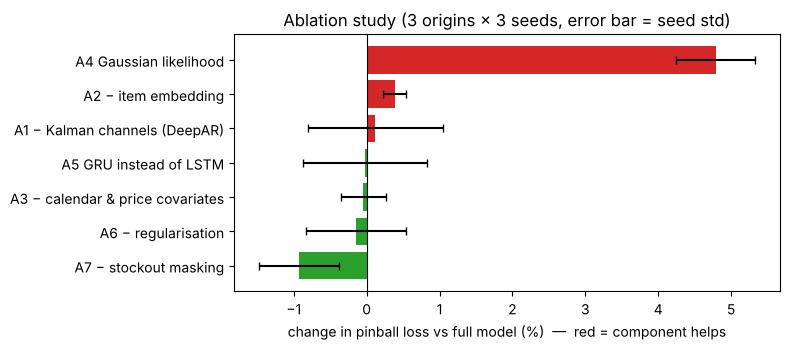

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
d = tab["Δ Pinball vs A0 (%)"].drop("A0 full KF-DeepAR").sort_values()
err = 100 * tab["Pinball std"].reindex(d.index) / ref
ax.barh(d.index, d.values, xerr=err.values, color=["C3" if v > 0 else "C2" for v in d.values], capsize=3)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("change in pinball loss vs full model (%)  —  red = component helps")
ax.set_title("Ablation study (3 origins × 3 seeds, error bar = seed std)")
plt.tight_layout(); plt.savefig(FIG / "05_ablation_bar.png", dpi=150); plt.show()

### Per-origin view (is the effect consistent across time?)

In [5]:
per_origin = po.groupby(level="origin").mean().T.round(4)
per_origin

origin,O1,O2,O3
model,,,
A0 full KF-DeepAR,0.3702,0.4006,0.4116
A1 − Kalman channels (DeepAR),0.3720,0.3990,0.4127
A2 − item embedding,0.3725,0.3995,0.4148
A3 − calendar & price covariates,0.3681,0.4006,0.4131
A4 Gaussian likelihood,0.3886,0.4184,0.4319
A5 GRU instead of LSTM,0.3718,0.3985,0.4119
A6 − regularisation,0.3700,0.3975,0.4131
A7 − stockout masking,0.3680,0.3920,0.4113


## 3. Regularisation: learning curves with and without
Without dropout / weight decay the training NLL keeps falling while the validation NLL stops improving earlier
(or rises) — the classic over-fitting signature. Early stopping limits the damage in both cases.

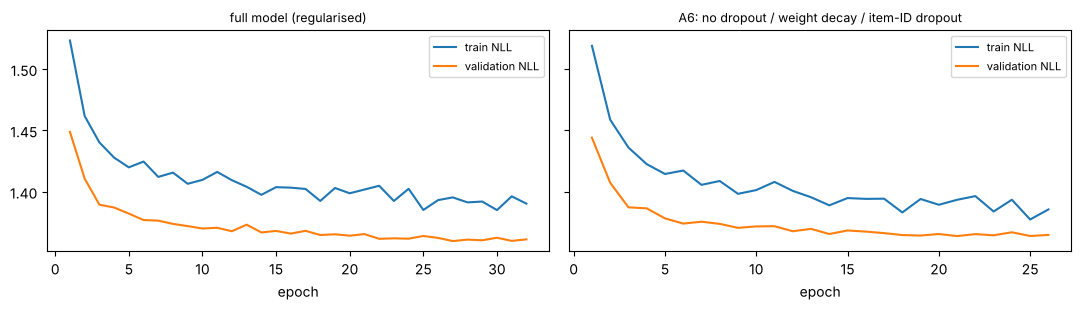

generalisation gap (val - train NLL) at the best epoch:
  full: -0.0356
  A6: -0.0296


In [6]:
H03 = pd.read_csv(TAB / "04_training_histories.csv").query("seed == 0 and origin == 'O1'")
H06 = pd.concat(hists).query("variant == 'A6 − regularisation' and origin == 'O1' and seed == 0")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for a, h, title in ((ax[0], H03, "full model (regularised)"), (ax[1], H06, "A6: no dropout / weight decay / item-ID dropout")):
    a.plot(h.epoch, h.train_nll, label="train NLL"); a.plot(h.epoch, h.val_nll, label="validation NLL")
    a.set_title(title, fontsize=9); a.set_xlabel("epoch"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "05_regularisation_curves.png", dpi=150); plt.show()
print("generalisation gap (val - train NLL) at the best epoch:")
for lbl, h in (("full", H03), ("A6", H06)):
    k = h.val_nll.idxmin(); print(f"  {lbl}: {h.loc[k, 'val_nll'] - h.loc[k, 'train_nll']:+.4f}")

## 4. Reading the ablations
The table and bar chart above are the evidence; the report (Section VI-F) discusses each line.
* A difference counts as real only if it is clearly larger than the seed std **and** has the same sign in most of the 9
  paired (origin, seed) runs (column "runs worse than A0").
* **A1** isolates the hybrid contribution under identical training conditions.
* **A4** checks the choice of likelihood for intermittent count data — the Gaussian has to put probability on negative sales.
* **A7** tests "mark, don't impute" for the deep model; compare both the all-days and the in-stock-days columns.

**Findings.**
* **A4 (Gaussian)** is the only clearly harmful change: +4.8% pinball, worse in **9 of 9** paired runs. The count likelihood is the most
  important design choice for intermittent sales.
* **A1, A2, A3, A5, A6** change the pinball loss by less than 0.4% — inside the seed noise. The Kalman channels help cold-start SKUs
  (notebook 04) but not the average SKU with a long history. The regularisers have little to do because this small model
  (27.6k parameters, random windows, early stopping) does not over-fit: validation NLL stays below training NLL in both settings.
* **A7** looks *better* on all days (−0.9%) but is neutral on in-stock days (−0.1%): learning stockout zeros lowers the forecast,
  which is rewarded on the 5.7% of test days that are stockouts themselves. Those zeros are censored demand, so the in-stock
  column is the relevant one; masking keeps the forecast an estimate of *demand*, which is what inventory planning needs.